# Commodities Futures Hedging Project

## 1. Project Introduction

The goal of this project is to find which December 2025 commodity futures can hedge each other (screened by pairwise R²), how many contracts are needed (unit-aware hedge ratios), and whether those hedges stay stable and work out-of-sample.

**Research questions**
1. Which pairs of contracts move together most closely (pairwise R²)?
2. How many hedge contracts are needed per target contract, once prices, lot sizes and quote units are taken into account?
3. Do the relationships stay stable through time, and do they work on unseen data?

**Assumptions**
| Item | Choice | Reason |
|---|---|---|
| Universe | 13 December-2025 futures (7 energy, 3 metals, 3 agriculture) | Project specification |
| Price field | `last` from the Bloomberg export | The settlement price is not in the file |
| Main sample | Common window, 2 Jan – 31 Oct 2025 (210 days, 209 returns) | Brent Dec-25 expires on 31 Oct; all 13 contracts are alive on every day |
| Robustness check | Pairwise-overlap windows (up to 1 Dec 2025), with hypothesis tests | Checks that the choice of sample does not drive the ranking |
| Returns | Simple daily returns | A contract's daily P&L equals its return times its value |
| Regression | OLS with intercept; HAC standard errors (5 lags) | Daily returns can be autocorrelated and have changing volatility |
| Hedge ratio | Return beta × contract-value ratio, cross-checked with a dollar P&L regression | Mentor guidance: the ratio should come from returns |
| Reference date | 31 Oct 2025 | Last day of the common window |
| Out-of-sample test | First 70% of days to estimate, last 30% to test, in time order | Avoids look-ahead bias |

## 2. Import Libraries

In [ ]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

from src.hedging_tools import *

DATA_PATH = '../data/cmdy_futures.csv'
COMMON_END = "2025-10-31"

SPECS = {
    "Brent":  {"ticker": "COZ25 Comdty",  "exchange": "ICE Futures Europe", "quote": "USD/bbl",       "lot": 1000,  "conversion": 1}, # conversion means convert to dollar, so 1 dollar is 1 dollar, 1 cent is 0.01 dollar
    "WTI":    {"ticker": "CLZ25 Comdty",  "exchange": "NYMEX",              "quote": "USD/bbl",       "lot": 1000,  "conversion": 1},
    "Dubai":  {"ticker": "DBLZ25 Comdty", "exchange": "Platts-linked (verify)", "quote": "USD/bbl",   "lot": 1000,  "conversion": 1},
    "ULSD":   {"ticker": "HOZ25 Comdty",  "exchange": "NYMEX",              "quote": "US cents/gal",  "lot": 42000, "conversion": 0.01},
    "Gasoil": {"ticker": "QSZ25 Comdty",  "exchange": "ICE Futures Europe", "quote": "USD/tonne",     "lot": 100,   "conversion": 1},
    "RBOB":   {"ticker": "XBZ25 Comdty",  "exchange": "NYMEX",              "quote": "US cents/gal",  "lot": 42000, "conversion": 0.01},
    "NatGas": {"ticker": "NGZ25 Comdty",  "exchange": "NYMEX",              "quote": "USD/MMBtu",     "lot": 10000, "conversion": 1},
    "Gold":   {"ticker": "GCZ25 Comdty",  "exchange": "COMEX",              "quote": "USD/oz",        "lot": 100,   "conversion": 1},
    "Silver": {"ticker": "SIZ25 Comdty",  "exchange": "COMEX",              "quote": "USD/oz",        "lot": 5000,  "conversion": 1},
    "Copper": {"ticker": "HGZ25 Comdty",  "exchange": "COMEX",              "quote": "US cents/lb",   "lot": 25000, "conversion": 0.01},
    "Coffee": {"ticker": "KCZ25 Comdty",  "exchange": "ICE Futures US",     "quote": "US cents/lb",   "lot": 37500, "conversion": 0.01},
    "Corn":   {"ticker": "C Z25 Comdty",  "exchange": "CBOT",               "quote": "US cents/bu",   "lot": 5000,  "conversion": 0.01},
    "Wheat":  {"ticker": "W Z25 Comdty",  "exchange": "CBOT",               "quote": "US cents/bu",   "lot": 5000,  "conversion": 0.01},
}

SECTORS = {  #split each into their category
    "Energy": ["Brent", "WTI", "Dubai", "ULSD", "Gasoil", "RBOB", "NatGas"],
    "Metals": ["Gold", "Silver", "Copper"],
    "Agriculture": ["Coffee", "Corn", "Wheat"],
}


What we wanna find out is the R square matrix such that we can find the pairs that move togther most closely
2. the hedge ratio, h, for each pairs and their 
3.Test the relationshipp on unseen data

## 3. Contract Specifications and Expiry Calendar

**Purpose.** Load the data, check each contract's specification, and build the expiry calendar. The data is read in here (rather than in Section 4) because both checks need the prices.

The raw file has 233,881 rows and contains whole futures curves. Only the 13 December-2025 contracts are kept. There are no duplicate (date, contract) rows.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
print("duplicate rows:", raw.duplicated(["price_date", "bbg_symbol"]).sum())
raw.head()

(233881, 11)
duplicate rows: 0


,price_date,bbg_symbol,DATES,last,bid,mid,low,high,open,volume,ask
0,01/01/2025,COH25 Comdty,01/01/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01/01/2025,COJ25 Comdty,01/01/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01/01/2025,COK25 Comdty,01/01/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01/01/2025,COM25 Comdty,01/01/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01/01/2025,CON25 Comdty,01/01/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
prices = load_field(DATA_PATH, SPECS, 'last') 
print(prices.shape)
prices = prices.dropna(how='all')  #Dropping first the dates that all are na. i.e probably the ones that it is closed. You can 

volume = load_field(DATA_PATH, SPECS, 'volume')
print(prices.shape)
print(volume.head())
prices.iloc[:3, :]


(335, 13)
(237, 13)
name          Brent      WTI  Dubai    ULSD   Gasoil    RBOB  NatGas   Gold  \
date                                                                          
2025-01-01      NaN      NaN    NaN     NaN      NaN     NaN     NaN    NaN   
2025-01-02  57787.0  55825.0    NaN  3680.0  10020.0  2245.0  5916.0  268.0   
2025-01-03  58232.0  53338.0    NaN  3711.0   5516.0  2386.0  5194.0  263.0   
2025-01-04      NaN      NaN    NaN     NaN      NaN     NaN     NaN    NaN   
2025-01-05      NaN      NaN    NaN     NaN      NaN     NaN     NaN    NaN   

name        Silver  Copper  Coffee     Corn   Wheat  
date                                                 
2025-01-01     NaN     NaN     NaN      NaN     NaN  
2025-01-02    42.0   108.0  1175.0  23634.0  1766.0  
2025-01-03   149.0   115.0   861.0  27592.0  3376.0  
2025-01-04     NaN     NaN     NaN      NaN     NaN  
2025-01-05     NaN     NaN     NaN      NaN     NaN  


name,Brent,WTI,Dubai,ULSD,Gasoil,RBOB,NatGas,Gold,Silver,Copper,Coffee,Corn,Wheat
date,,,,,,,,,,,,,
2025-01-02,72.61,68.95,71.238,226.25,681.0,191.11,4.375,2789.5,31.170,414.25,296.65,446.50,595.00
2025-01-03,72.97,69.39,71.589,226.30,676.0,191.43,4.265,2771.4,31.308,418.30,288.40,440.75,581.75
2025-01-06,72.89,69.42,71.520,226.34,680.0,191.22,4.342,2762.9,31.773,426.00,290.70,445.50,593.25


**Reading the output.** 335 calendar dates fall to **237** once the dates with no price for any of the 13 contracts (weekends and 1 January) are removed. `volume` is loaded in the same way and is used for the liquidity check in Section 4.

**Contract specification check.** The contracts are quoted in different units (dollars per barrel, cents per gallon, dollars per tonne, cents per bushel) and have different lot sizes, so their prices cannot be compared directly.

$$\text{Contract value (USD)} = \text{price} \times \text{lot size} \times \text{conversion to dollars}$$

The table shows the value of one contract on the first trading day. This is a sanity check: if a conversion were missing (for example, treating cents as dollars), the value would be 100 times too large and would stand out.

In [4]:
spec_table = pd.DataFrame(SPECS).T
spec_table['first price'] = prices.apply(lambda s: s.dropna().iloc[0])
spec_table["first contract value"] = contract_value(prices.apply(lambda s: s.dropna()).iloc[0], SPECS)
spec_table

,ticker,exchange,quote,lot,conversion,first price,first contract value
Brent,COZ25 Comdty,ICE Futures Europe,USD/bbl,1000,1,72.610,72610.00
WTI,CLZ25 Comdty,NYMEX,USD/bbl,1000,1,68.950,68950.00
Dubai,DBLZ25 Comdty,Platts-linked (verify),USD/bbl,1000,1,71.238,71238.00
ULSD,HOZ25 Comdty,NYMEX,US cents/gal,42000,0.01,226.250,95025.00
Gasoil,QSZ25 Comdty,ICE Futures Europe,USD/tonne,100,1,681.000,68100.00
RBOB,XBZ25 Comdty,NYMEX,US cents/gal,42000,0.01,191.110,80266.20
NatGas,NGZ25 Comdty,NYMEX,USD/MMBtu,10000,1,4.375,43750.00
Gold,GCZ25 Comdty,COMEX,USD/oz,100,1,2789.500,278950.00
Silver,SIZ25 Comdty,COMEX,USD/oz,5000,1,31.170,155850.00
Copper,HGZ25 Comdty,COMEX,US cents/lb,25000,0.01,414.250,103562.50


In [ ]:
coverage = coverage_table(prices, volume)
coverage

#some notes will be that they are started on the same dates and their last dates are not all equal

c:\Users\zheru\quant-projects\commodities_hedging_project\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,first date,last date,days with value,gaps inside,unchanged days,median volume
Brent,2025-01-02,2025-10-31,216,0,1,134614.5
WTI,2025-01-02,2025-11-20,224,6,1,91782.0
Dubai,2025-01-02,2025-12-01,230,7,0,NaN
ULSD,2025-01-02,2025-11-28,229,7,1,16909.0
Gasoil,2025-01-02,2025-12-01,237,0,2,35977.0
RBOB,2025-01-02,2025-11-28,229,7,1,8879.0
NatGas,2025-01-02,2025-11-25,227,6,0,16534.0
Gold,2025-01-02,2025-12-01,230,7,1,5239.0
Silver,2025-01-02,2025-12-01,230,7,0,1998.0
Copper,2025-01-02,2025-12-01,230,7,1,5880.5


**Reading the two tables.**

- **Contract values are plausible:** from about USD 22,000 (corn) to USD 279,000 (gold). Contract sizes differ by more than ten times, which is why the hedge ratio must be converted into numbers of contracts in Section 8.
- **Expiry calendar:** all contracts start on 2 Jan 2025 but stop on different dates. **Brent stops first, on 31 Oct**, then WTI (20 Nov), natural gas (25 Nov), ULSD and RBOB (28 Nov). The others run to the end of the data (1 Dec).
- **Gaps inside:** the US-listed contracts have 6–7 missing days (US public holidays). ICE Brent and Gasoil, which trade in London, have none.
- **Unchanged days:** only 0–5 per contract, so there is no sign of stale prices.
- **Volume:** Dubai has no volume data, so its liquidity cannot be checked.

> **Implication:** a sample that contains all 13 contracts on every day must end on 31 Oct 2025. This defines the common window used in Section 4.

## 4. Load and Clean Data

**Purpose.** Check liquidity and data quality, choose the sample, and compute returns. Every cleaning decision is recorded, with its reason, in the cleaning log at the end of this section.

In [6]:
monthly_median_deal = volume.resample('ME').median().T
monthly_median_deal.iloc[:, [0,3,6,9]]

date,2025-01-31,2025-04-30,2025-07-31,2025-10-31
name,,,,
Brent,72451.5,119751.0,142515.0,331204.0
WTI,55825.0,86462.0,86982.5,260065.0
Dubai,NaN,NaN,NaN,NaN
ULSD,4341.0,8966.0,22423.0,53741.0
Gasoil,13868.0,27214.0,38471.0,108630.0
RBOB,2821.0,5098.0,9698.0,61236.0
NatGas,7023.0,12705.0,19053.5,113204.0
Gold,823.0,3491.0,42415.5,309914.0
Silver,91.0,893.0,3596.0,99323.0


**Liquidity.** Volume rises strongly through the year as the December contract approaches expiry. The median daily volume of silver goes from 91 contracts in January to about 99,000 in October, and gold from 823 to about 310,000. Early in the year the metals contracts are thinly traded, so their early prices are less reliable. This is flagged as a limitation rather than removed, because deleting those months would shorten an already short sample.

In [7]:
print((prices<=0).sum().sum()) #check for any prices below 0
returns_table = prices.apply(lambda s : s.dropna().pct_change(), axis = 0)
stats_table = pd.DataFrame({
    "max magnitude of pct change": ((returns_table.abs().max()) * 100).round(3),
    'date': returns_table.abs().idxmax().dt.date,
    "direction" : np.where(returns_table.apply(lambda s: s.loc[s.abs().idxmax()]) > 0, "up", "down"),
})
stats_table.sort_values("max magnitude of pct change", ascending = False)
#This table shows the maximum percentage change for each and their date and whether it is increase or down

0


,max magnitude of pct change,date,direction
name,,,
Copper,21.784,2025-07-31,down
Silver,8.505,2025-04-04,down
Gasoil,8.291,2025-06-24,down
Coffee,8.233,2025-09-17,down
NatGas,7.859,2025-10-20,up
ULSD,6.577,2025-10-23,up
WTI,6.106,2025-04-04,down
RBOB,6.052,2025-04-03,down
Gold,5.742,2025-10-21,down


**Data validation.**

- There are no zero or negative prices.
- The largest one-day move is **copper, −21.8% on 31 Jul 2025**. It is **kept**: it coincides with the US decision on copper tariffs, so it is a real market move, and deleting it would understate risk. It does dominate copper's statistics in Section 5.
- The other largest moves are 4–9%, which is normal for commodities. Several fall on the same dates across contracts (3–4 April, 24 June), which points to market-wide events rather than data errors.

In [8]:
window = prices.loc[:COMMON_END] #COMMON END is defined at the begining as after this the brent expires
missing_days = window[window.isna().any(axis = 1)]
print(len(missing_days), 'days where there is at least one NA value in the prices')
print(missing_days.notna().sum(axis = 1).to_string())
common = window.dropna()
print(common.shape, " its start dates and end dates are:",common.index[0].date(), common.index[-1].date())

6 days where there is at least one NA value in the prices
date
2025-01-20    2
2025-02-17    2
2025-05-26    2
2025-06-19    2
2025-07-04    2
2025-09-01    2
(210, 13)  its start dates and end dates are: 2025-01-02 2025-10-31


**Common window.** Between 2 Jan and 31 Oct there are 6 dates on which only 2 of the 13 contracts have a price. These are US public holidays (20 Jan, 17 Feb, 26 May, 19 Jun, 4 Jul, 1 Sep): only the two London contracts (ICE Brent and Gasoil) traded.

These dates are **dropped, not forward-filled**. Filling would create artificial zero returns for 11 contracts and would understate their volatility and their correlations. This leaves **210 days** on which all 13 contracts have a price.

In [9]:
returns = common.pct_change().dropna() # drop the first row of NA values
print(returns.shape)
returns.head(7).round(4)

(209, 13)


name,Brent,WTI,Dubai,ULSD,Gasoil,RBOB,NatGas,Gold,Silver,Copper,Coffee,Corn,Wheat
date,,,,,,,,,,,,,
2025-01-03,0.0050,0.0064,0.0049,0.0002,-0.0073,0.0017,-0.0251,-0.0065,0.0044,0.0098,-0.0278,-0.0129,-0.0223
2025-01-06,-0.0011,0.0004,-0.0010,0.0002,0.0059,-0.0011,0.0181,-0.0031,0.0149,0.0184,0.0080,0.0108,0.0198
2025-01-07,0.0054,0.0045,0.0043,0.0056,-0.0011,0.0037,-0.0074,0.0068,0.0065,0.0093,0.0072,0.0017,0.0046
2025-01-08,-0.0081,-0.0087,-0.0080,-0.0062,-0.0092,-0.0043,0.0176,0.0031,-0.0000,0.0120,-0.0143,-0.0028,-0.0105
2025-01-09,0.0047,0.0043,0.0040,0.0064,0.0119,0.0054,0.0043,0.0064,0.0098,0.0095,0.0045,0.0045,-0.0042
2025-01-10,0.0170,0.0143,0.0165,0.0257,0.0099,0.0208,0.0107,0.0089,0.0090,-0.0020,0.0093,0.0073,0.0030
2025-01-13,-0.0044,-0.0064,-0.0013,0.0027,0.0113,0.0004,0.0045,-0.0137,-0.0323,0.0084,0.0111,0.0155,0.0212


**Returns.** Simple daily returns are used because a contract's daily P&L equals its return times its value. 210 prices give **209 returns**, on identical dates for all 13 contracts.

**Cleaning log**

| # | Issue | Rule | Reason | Effect |
|---|---|---|---|---|
| 1 | The file contains whole futures curves | Keep only the 13 Dec-25 contracts | Project scope | 233,881 rows → 13 series |
| 2 | Weekends and 1 Jan are empty | Drop dates on which all 13 prices are missing | Non-trading days | 237 trading days |
| 3 | 6 US holidays: only ICE Brent and Gasoil traded | Drop those dates; never forward-fill | Forward-filling creates artificial zero returns | 216 → 210 days |
| 4 | Contracts expire on different dates | Common window ends 31 Oct 2025 (Brent expiry) | All 13 contracts must be alive; avoids near-expiry effects | Sample: 2 Jan – 31 Oct |
| 5 | Copper −21.8% on 31 Jul 2025 | Keep | Real market move; deleting it would bias risk downward | None |
| 6 | Possible stale prices | Count unchanged-price days (0–5 per contract) | No evidence of stale prices | None |
| 7 | Thin volume early in the year (metals) | Flag, do not delete | Far-dated contracts are illiquid early on | Limitation |
| 8 | Dubai has no volume data | Flag | Liquidity cannot be verified | Limitation |
| 9 | Price field | Use `last` | Settlement price is not in the export | Limitation |

## 5. Exploratory Data Analysis

**Purpose.** Look at prices, volatility and correlations before running any regression.

**Economic hypotheses.** Before ranking the regressions, these are the relationships expected on economic grounds:

- **Crude grades** (Brent, WTI, Dubai) should be very highly correlated: the same commodity, linked by global arbitrage.
- **Refined products** (ULSD, RBOB, Gasoil) should follow crude, their main input cost, but less tightly because refining margins also move.
- **ULSD and Gasoil** are essentially the same product (diesel) in New York and London, so they should be closely related.
- **US natural gas** is driven by weather and storage, so it should be only weakly related to oil.
- **Gold and silver** share a precious-metals driver; silver also has industrial uses, so the link should be moderate. Copper is industrial.
- **Corn and wheat** compete for land and for feed demand, so they should be related. Coffee has its own supply story.

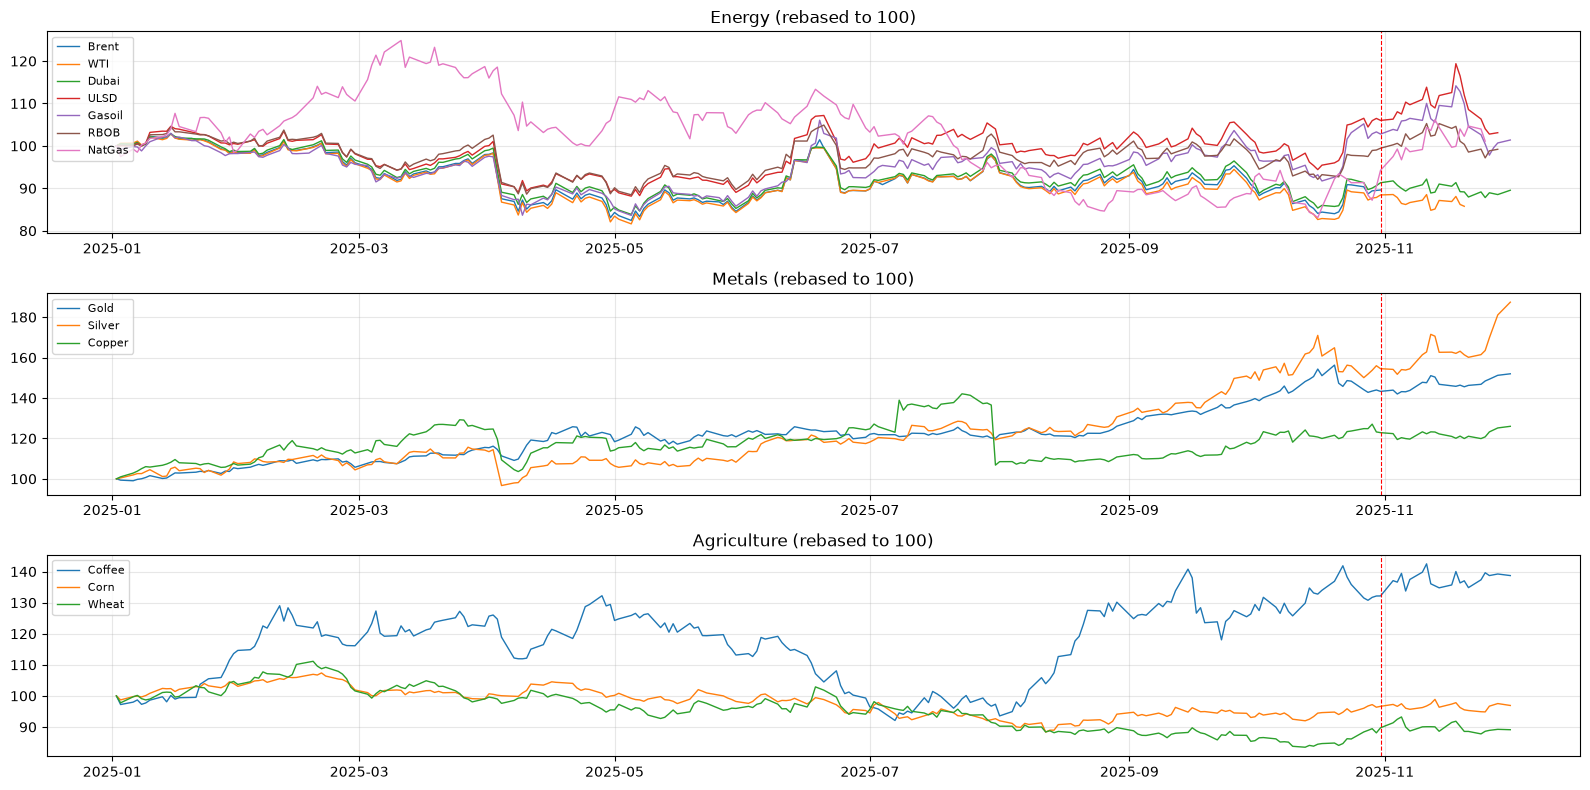

In [10]:
#PLOT!!
# SECTORS = {  #spl;it each into their category
#     "Energy": ["Brent", "WTI", "Dubai", "ULSD", "Gasoil", "RBOB", "NatGas"],
#     "Metals": ["Gold", "Silver", "Copper"],
#     "Agriculture": ["Coffee", "Corn", "Wheat"],
# }
fig, axes = plt.subplots(3,1, figsize = (16,8))
for i, sector in enumerate(SECTORS):
    ax = axes[i]
    for name in SECTORS[sector]:
        p = prices[name].dropna()
        ax.plot(100 * p/ p.iloc[0], label = name, linewidth = 1)  #compare to its day 1 price
    ax.axvline(pd.Timestamp(COMMON_END), color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{sector} (rebased to 100)")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
return_stats = pd.DataFrame({
    "annual volatility" : returns.std() * np.sqrt(252) * 100,
    "skew" : returns.skew(),
    "excess kurtosis" : returns.kurt(),
    "min (%)" : returns.min(),
    "max(%)" : returns.max(),
})
return_stats.sort_values("annual volatility", ascending= False).round(2)


,annual volatility,skew,excess kurtosis,min (%),max(%)
name,,,,,
Copper,38.29,-3.14,36.20,-0.22,0.13
Coffee,36.62,-0.25,0.31,-0.08,0.06
NatGas,33.77,0.20,1.00,-0.06,0.08
Silver,30.19,-0.92,4.33,-0.09,0.07
WTI,26.66,-0.40,2.16,-0.06,0.06
Gasoil,25.80,-0.58,4.45,-0.08,0.07
Brent,25.58,-0.35,2.25,-0.06,0.05
ULSD,25.44,0.02,2.92,-0.06,0.07
Dubai,24.28,-0.43,1.98,-0.05,0.05


**Reading the table.** Copper appears to be the most volatile contract (38% a year) with extreme skew (−3.1) and excess kurtosis (36), but this comes almost entirely from the single −21.8% day. Coffee (37%) and natural gas (34%) are volatile throughout the year. Corn is the calmest (15%). Volatility matters for hedging because beta depends on the ratio of the two contracts' volatilities.

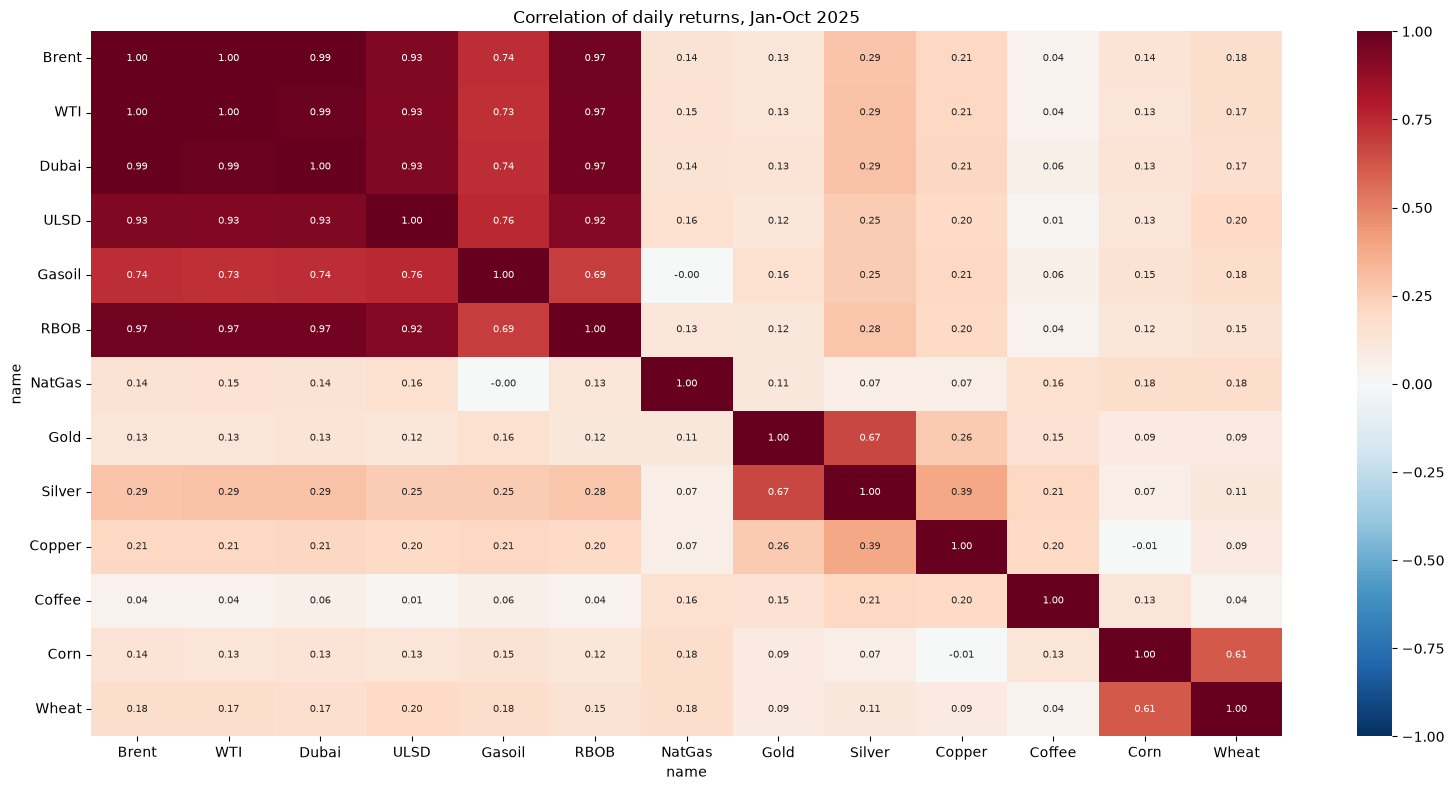

In [12]:
corr_table = returns.corr()
fig, ax = plt.subplots(figsize=(16,8))
sns.heatmap(corr_table, annot = True, fmt = '.2f', cmap="RdBu_r",vmin=-1, vmax = 1, ax = ax , annot_kws={"size":7})
ax.set_title("Correlation of daily returns, Jan-Oct 2025")
plt.tight_layout()
plt.show()

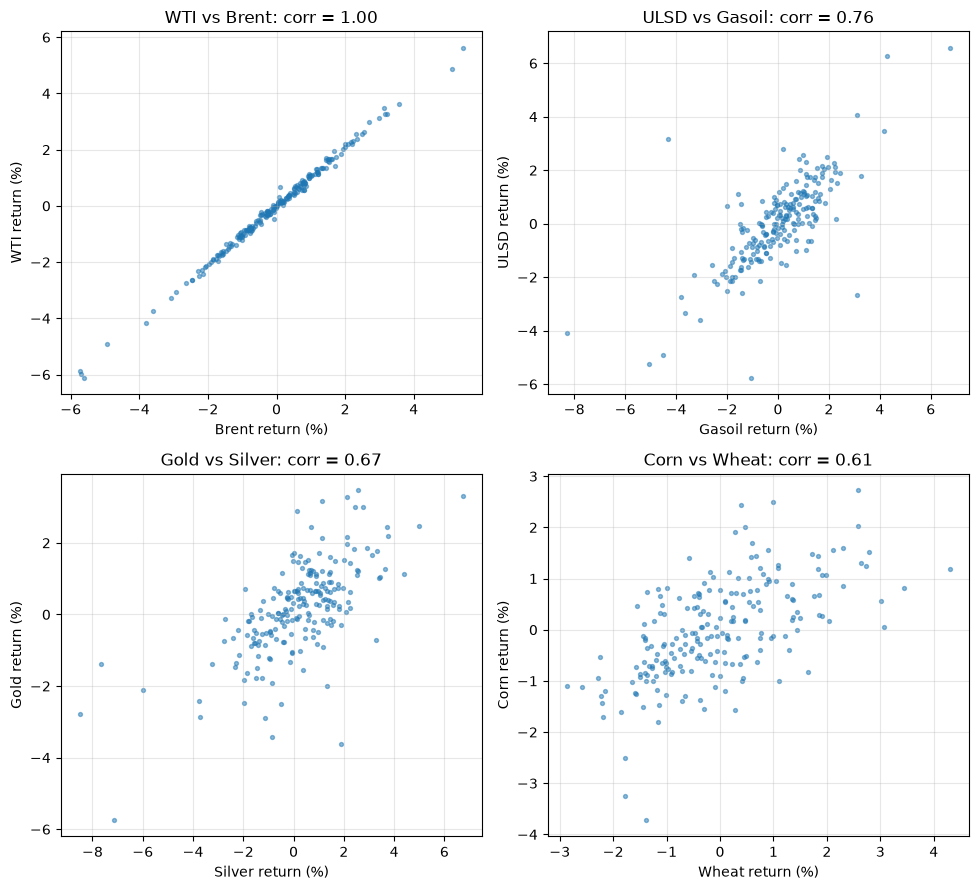

In [13]:
pairs = [("WTI", "Brent"), ("ULSD", "Gasoil"), ("Gold", "Silver"), ("Corn", "Wheat")] #as specified in the document
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
flat_axes = axes.flatten()
for i in range(len(pairs)):
    target, hedge = pairs[i]
    ax = flat_axes[i]
    ax.scatter(returns[hedge] * 100, returns[target] * 100, s=8, alpha=0.5)
    ax.set_xlabel(f"{hedge} return (%)")
    ax.set_ylabel(f"{target} return (%)")
    ax.set_title(f"{target} vs {hedge}: corr = {corr_table.loc[target, hedge]:.2f}")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

- **The energy complex moves together.** The three crude grades are almost perfectly correlated (0.99–1.00), and the refined products follow crude at 0.73–0.97. This matches the hypothesis.
- **Natural gas and coffee stand alone:** their correlation with every other contract is at most about 0.2, consistent with their own supply and demand drivers.
- **Gold–silver (0.67) and corn–wheat (0.61) are moderate**, as expected.
- **Surprise:** ULSD and Gasoil, essentially the same product, have a correlation of only 0.76. Section 6 shows that this is partly a settlement-timing effect.

> **Takeaway:** good hedges are likely to be found inside the energy sector; across sectors there is little to work with.

## 6. Pairwise Regressions and R² Screening

**Purpose.** Measure how closely each pair moves together, and rank all 78 pairs.

For a target contract and a hedge contract, the regression is

$$r_{\text{target},t} = \alpha + \beta\, r_{\text{hedge},t} + \varepsilon_t$$

- $R^2$ is the share of the target's return variance that the hedge explains. It is also the largest share of risk that this hedge could remove.
- $\beta$ says how many dollars of the hedge move with one dollar of the target. It sets the size of the hedge (Section 8).

In [14]:
wti_on_brent = pair_ols(returns['WTI'], returns['Brent'])
brent_on_wti = pair_ols(returns['Brent'], returns['WTI'])
pd.DataFrame({"WTI on Brent": wti_on_brent, "Brent on WTI" : brent_on_wti})


,WTI on Brent,Brent on WTI
n,209.000000,209.000000
corr,0.997718,0.997718
r2,0.995441,0.995441
beta,1.039871,0.957274
beta_se,0.008188,0.007379
alpha,-0.000036,0.000033
resid_sd,0.001134,0.001088
dw,2.089699,2.058099


**R² is symmetric; beta is not.** R² is 0.9954 in both directions, but beta is 1.040 (WTI on Brent) and 0.957 (Brent on WTI). Beta depends on which contract is the target and on the two contracts' relative volatility, so it cannot be used to rank relationships. R² is used for ranking, and beta is kept for sizing. As a check, the two betas multiply to R²: 1.040 × 0.957 = 0.995.

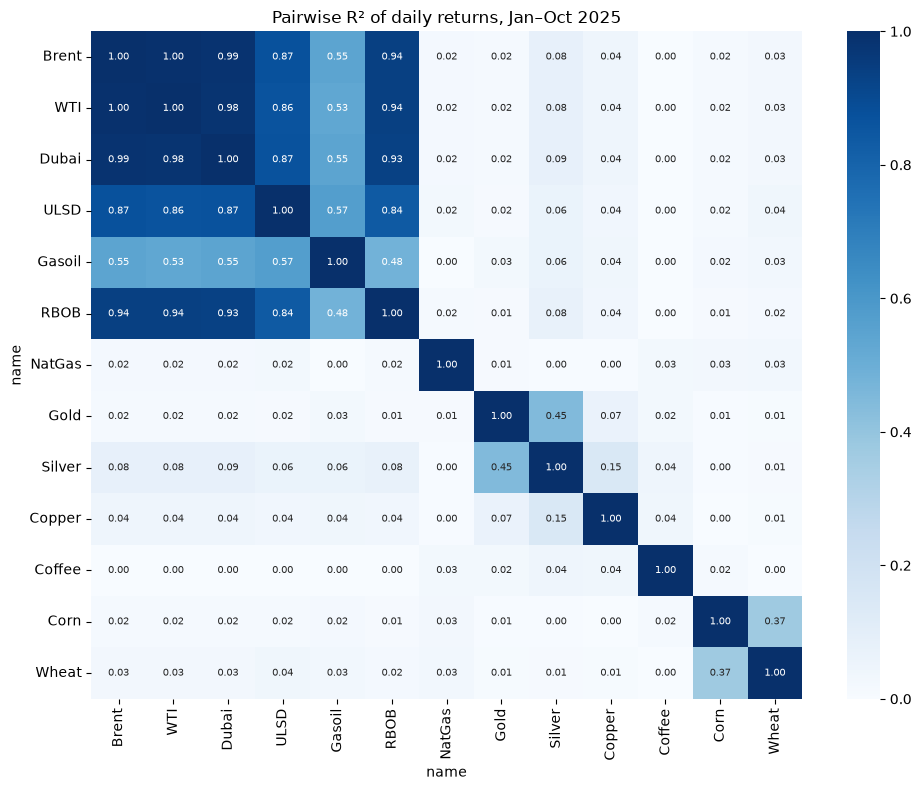

In [15]:
r2 = corr_table ** 2
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(r2, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_title("Pairwise R² of daily returns, Jan–Oct 2025")
plt.tight_layout()
plt.show()

In [16]:
#Compare the R square result from the graph and the OLS
print("R square from regressgion: " , pair_ols(returns['WTI'], returns['Dubai'])["r2"].round(6))
print("R square from squaring correlation: " , r2.loc['WTI', "Dubai"].round(6))

R square from regressgion:  0.983759
R square from squaring correlation:  0.983759


**Check.** The regression R² equals the squared correlation, so the heatmap above gives the R² of all 78 regressions at once.

In [17]:
paired_Rsquare = []
for i in range(len(r2.columns)):
    for j in range(i+1, len(r2.columns)):
        paired_Rsquare.append({"pair" :f"{list(r2)[i]} / {list(r2)[j]}", 'R square' : r2.loc[list(r2)[i],list(r2)[j]], "corr" : corr_table.loc[list(r2)[i],list(r2)[j]] })

pair_table = pd.DataFrame(paired_Rsquare).sort_values("R square", ascending= False).reset_index(drop = True)
pair_table.head(12)

,pair,R square,corr
0,Brent / WTI,0.995441,0.997718
1,Brent / Dubai,0.986697,0.993326
2,WTI / Dubai,0.983759,0.991846
3,Brent / RBOB,0.939639,0.969350
4,WTI / RBOB,0.938183,0.968599
5,Dubai / RBOB,0.933828,0.966348
6,Brent / ULSD,0.873047,0.934370
7,Dubai / ULSD,0.867441,0.931365
8,WTI / ULSD,0.863896,0.929460
9,ULSD / RBOB,0.837906,0.915372


In [18]:
lead_lag = pd.DataFrame({
    "same day": [returns["Gasoil"].corr(returns["ULSD"]), returns["Brent"].corr(returns["WTI"])],
    "London today vs NY yesterday": [returns["Gasoil"].corr(returns["ULSD"].shift(1)), returns["Brent"].corr(returns["WTI"].shift(1))],
    "London yesterday vs NY today": [returns["Gasoil"].shift(1).corr(returns["ULSD"]), returns["Brent"].shift(1).corr(returns["WTI"])],
}, index=["Gasoil vs ULSD", "Brent vs WTI"])
print(lead_lag.round(3))
two_day = common.iloc[::2].pct_change().dropna()
print("R² with daily returns:", round(corr_table.loc["ULSD", "Gasoil"] ** 2, 3))
print("R² with 2-day returns:", round(two_day["ULSD"].corr(two_day["Gasoil"]) ** 2, 3))

                same day  London today vs NY yesterday  \
Gasoil vs ULSD     0.756                         0.215   
Brent vs WTI       0.998                         0.051   

                London yesterday vs NY today  
Gasoil vs ULSD                         0.086  
Brent vs WTI                           0.053  
R² with daily returns: 0.571
R² with 2-day returns: 0.843


### Interpretation

- **The top ten pairs are all energy:** the crude grades (R² ≥ 0.98), then crude against RBOB (about 0.94) and crude against ULSD (about 0.87). These are economically intuitive, because refined products are made from crude.
- **Across sectors there is almost nothing:** the highest cross-sector R² is 0.09.
- **Gasoil looks weaker than it should** (R² 0.57 with ULSD), and the diagnostic above explains part of it. ICE Gasoil settles in London before New York closes, so late New York moves reach Gasoil only on the next day: the correlation between Gasoil today and ULSD yesterday is 0.22, against 0.05 for Brent and WTI. With 2-day returns, which absorb the timing gap, R² rises from 0.57 to **0.84**.
- **Multiple comparisons:** with 78 pairs, a few will look related by chance. The ranking therefore relies on the size of R² together with economic logic, not on p-values alone.

> **Takeaway:** R² identifies crude and refined products as the natural hedging group. Daily R² understates the true link for contracts that settle at different times.

## 7. Candidate Hedge Ranking

**Purpose.** For each contract, list the three best hedges by R². Then check that the ranking does not depend on how the sample was chosen.

In [19]:
rank_hedges(returns, "ULSD").round(3)

,n,corr,r2,beta,beta_se,alpha,resid_sd,dw
Brent,209.0,0.934,0.873,0.929,0.030,0.001,0.006,2.261
Dubai,209.0,0.931,0.867,0.976,0.034,0.001,0.006,2.164
WTI,209.0,0.929,0.864,0.887,0.032,0.001,0.006,2.227


In [20]:
rankings = {}
for hedge in list(returns):
    top = rank_hedges(returns, hedge, 3)
    rankings[hedge] = {
        "hedge 1": f"{top.index[0]} ({top['r2'].iloc[0]:.2f})",
        "hedge 2": f"{top.index[1]} ({top['r2'].iloc[1]:.2f})",
        "hedge 3": f"{top.index[2]} ({top['r2'].iloc[2]:.2f})",
        "sign": "+" if top["corr"].iloc[0] > 0 else "-",  #only the sign for hedge 1 is considered
    }
rankings = pd.DataFrame(rankings).T
rankings

,hedge 1,hedge 2,hedge 3,sign
Brent,WTI (1.00),Dubai (0.99),RBOB (0.94),+
WTI,Brent (1.00),Dubai (0.98),RBOB (0.94),+
Dubai,Brent (0.99),WTI (0.98),RBOB (0.93),+
ULSD,Brent (0.87),Dubai (0.87),WTI (0.86),+
Gasoil,ULSD (0.57),Dubai (0.55),Brent (0.55),+
RBOB,Brent (0.94),WTI (0.94),Dubai (0.93),+
NatGas,Wheat (0.03),Corn (0.03),Coffee (0.03),+
Gold,Silver (0.45),Copper (0.07),Gasoil (0.03),+
Silver,Gold (0.45),Copper (0.15),Dubai (0.09),+
Copper,Silver (0.15),Gold (0.07),Dubai (0.04),+


**Robustness check: pairwise-overlap design.** The main analysis uses one common window for all pairs. An equally reasonable alternative is to let each pair use every date on which *both* of its contracts have a price, which adds up to 20 extra days in November. If the conclusions are robust, the ranking should hardly change. The Spearman correlation compares the two rankings (1 = identical order).

In [21]:
#Here is the only removing the na values shared by the chosen pairwise 
overlap_rows = []
names = list(returns)
for i in range(len(names)):
    for j in range(i+1, len(names)):
        a , b = names[i], names[j]
        price = prices[[a,b]].dropna()
        shared = price.pct_change().dropna()
        overlap_rows.append({
            "pair": f"{a} / {b}",
            "N": len(shared),
            "R2 common": r2.loc[a, b],
            "R2 overlap": shared[a].corr(shared[b]) ** 2,
        })
overlap = pd.DataFrame(overlap_rows).set_index('pair')
overlap["change"] = overlap["R2 overlap"] - overlap["R2 common"]
print("observations per pair:", overlap["N"].min(), "to", overlap["N"].max())
print("Spearman correlation of the two rankings:",
      round(overlap["R2 common"].corr(overlap["R2 overlap"], method="spearman"), 3))
overlap.sort_values("change").head(3).round(3)



observations per pair: 209 to 229
Spearman correlation of the two rankings: 0.964


,N,R2 common,R2 overlap,change
pair,,,,
Dubai / ULSD,228,0.867,0.759,-0.109
ULSD / RBOB,228,0.838,0.764,-0.074
WTI / ULSD,223,0.864,0.800,-0.064


**Number of observations per pair.** In the pairwise-overlap design each R² is based on a different number of days, so the sample size has to be reported next to it.

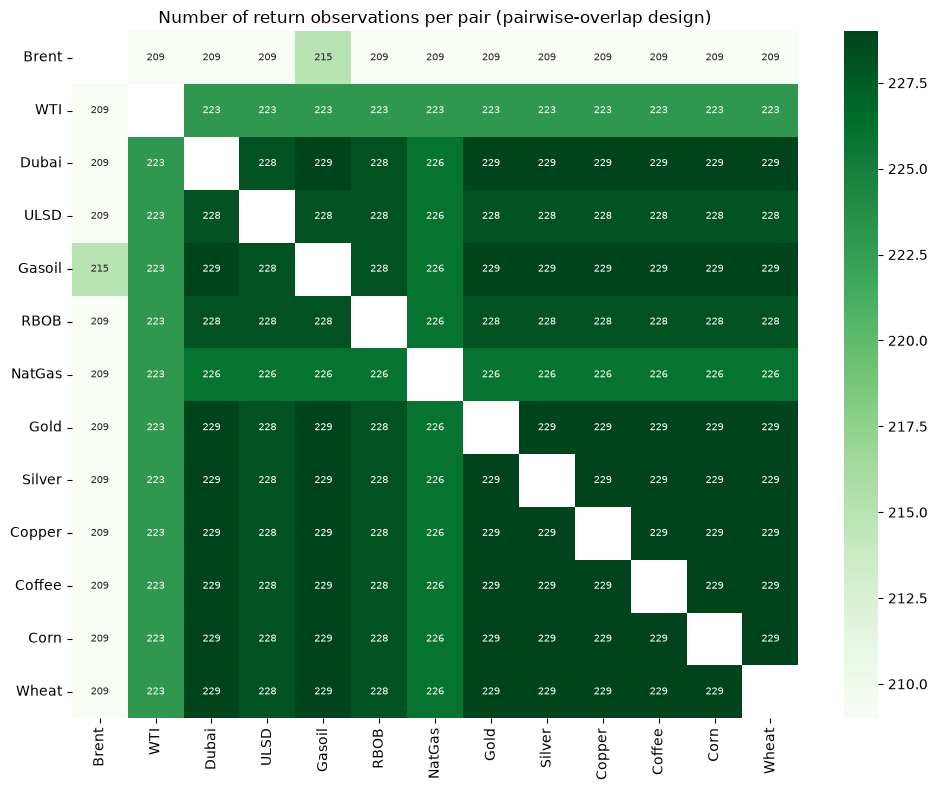

,Brent,WTI,Dubai,Gasoil,NatGas,Gold,Silver
Brent,NaN,209.0,209.0,215.0,209.0,209.0,209.0
WTI,209.0,NaN,223.0,223.0,223.0,223.0,223.0
Gasoil,215.0,223.0,229.0,NaN,226.0,229.0,229.0
Gold,209.0,223.0,229.0,229.0,226.0,NaN,229.0


In [22]:
n_matrix = pd.DataFrame(index=names, columns=names, dtype=float)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        n = overlap.loc[f"{a} / {b}", "N"]
        n_matrix.loc[a, b] = n
        n_matrix.loc[b, a] = n
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(n_matrix, annot=True, fmt=".0f", cmap="Greens", ax=ax, annot_kws={"size": 7})
ax.set_title("Number of return observations per pair (pairwise-overlap design)")
plt.tight_layout()
plt.show()
n_matrix.loc[["Brent", "WTI", "Gasoil", "Gold"], ["Brent", "WTI", "Dubai", "Gasoil", "NatGas", "Gold", "Silver"]]

**Hypothesis test 1: do the two designs give a different R² on average?** (mid-project review)

Comparing two R² values by eye is not enough, because each R² is an estimate with its own error. Each of the 78 pairs has two values (common window and pairwise overlap), so the test is applied to the 78 differences.

- $H_0$: the mean change in R² is zero.
- **Paired t-test:** uses each pair's own change, $t = \bar d \,/\, (s_d/\sqrt{78})$.
- **Wilcoxon signed-rank test:** asks the same question without assuming the changes are normally distributed.

A p-value below 0.05 rejects $H_0$.

In [ ]:
print("mean R2 common: ", round(overlap["R2 common"].mean(), 4))
print("mean R2 overlap:", round(overlap["R2 overlap"].mean(), 4))
print("mean change:    ", round(overlap["change"].mean(), 4))

t_test = stats.ttest_rel(overlap["R2 overlap"], overlap["R2 common"])
print("paired t-test:  t =", round(t_test.statistic, 2), " p =", round(t_test.pvalue, 4))

w_test = stats.wilcoxon(overlap["R2 overlap"], overlap["R2 common"])
print("Wilcoxon test:  p =", round(w_test.pvalue, 6))

mean R2 common:  0.1851
mean R2 overlap: 0.176
mean change:     -0.0091
paired t-test:  t = -4.02  p = 0.0001
Wilcoxon test:  p = 3.5e-05


**Hypothesis test 2: where does the difference come from?**

The pairwise-overlap sample is the common window plus the extra days, mostly in November. If R² changes, it can only be because the extra days behave differently. So the correlation in the 209 common-window days is compared with the correlation in the extra days. These are different days, so they can be treated as two independent samples.

A correlation is bounded between −1 and 1, so it is first transformed with the **Fisher z-transformation**, $z = \text{arctanh}(r)$, which is approximately normal with standard error $1/\sqrt{n-3}$:

$$Z = \frac{\text{arctanh}(r_1) - \text{arctanh}(r_2)}{\sqrt{\dfrac{1}{n_1-3} + \dfrac{1}{n_2-3}}}$$

$H_0$: the two correlations are equal. Three ULSD pairs are tested, with three other pairs as controls.

In [ ]:
check_pairs = [("Dubai", "ULSD"), ("ULSD", "RBOB"), ("WTI", "ULSD"),
               ("ULSD", "Gasoil"), ("Gold", "Silver"), ("Corn", "Wheat")]
fisher_rows = {}
for k in range(len(check_pairs)):
    a, b = check_pairs[k]
    shared = prices[[a, b]].dropna().pct_change().dropna()
    extra = shared.loc[~shared.index.isin(returns.index)]     # days outside the common window
    r_common = returns[a].corr(returns[b])
    r_extra = extra[a].corr(extra[b])
    n1, n2 = len(returns), len(extra)
    z = (np.arctanh(r_common) - np.arctanh(r_extra)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    p_value = 2 * stats.norm.sf(abs(z))
    fisher_rows[f"{a} / {b}"] = {
        "N common": n1, "N extra": n2,
        "corr common": r_common, "corr extra": r_extra,
        "z": z, "p-value": p_value,
    }
pd.DataFrame(fisher_rows).T.round(4)

,N common,N extra,corr common,corr extra,z,p-value
Dubai / ULSD,209.0,19.0,0.9314,0.5111,4.2553,0.0000
ULSD / RBOB,209.0,19.0,0.9154,0.6546,2.9913,0.0028
WTI / ULSD,209.0,14.0,0.9295,0.7069,2.4991,0.0125
ULSD / Gasoil,209.0,19.0,0.7558,0.8231,-0.6936,0.4879
Gold / Silver,209.0,20.0,0.6679,0.8470,-1.7377,0.0823
Corn / Wheat,209.0,20.0,0.6094,0.6553,-0.3039,0.7612


### Interpretation

**Ranking**

- **Energy has several strong hedges for every target** (for ULSD: Brent 0.87, Dubai 0.87, WTI 0.86). This matters if one contract is illiquid.
- **Gold–silver and corn–wheat** are each other's best hedge, but with modest R² (0.45 and 0.37).
- **Natural gas, coffee and copper have no useful cross-hedge** (best R² 0.03, 0.04 and 0.15).
- All the leading correlations are positive, so a long position in the target is hedged with a **short** position in the hedge.
- Dubai ranks highly but has no volume data, so a desk would prefer Brent or WTI as the hedge it can actually trade.

**Robustness**

- **The ranking is robust:** the pairwise-overlap design gives almost the same order (Spearman 0.964).
- **Sample sizes** range from 209 to 229 returns. Each pair is limited by whichever contract expires first. Brent–Gasoil has 215 because both London contracts also trade on US holidays.
- **Test 1:** R² falls by 0.009 on average (0.185 → 0.176) when the extra days are added. The fall is statistically significant (paired t = −4.02, p = 0.0001; Wilcoxon p < 0.001) but small: only 4 of the 78 pairs change by more than 0.05. The 78 pairs share contracts, so they are not independent and the p-value is optimistic.
- **Test 2:** the fall comes from ULSD. In the extra November days, its correlation with Dubai crude is 0.51, against 0.93 in the common window (p < 0.001); with RBOB 0.65 against 0.92; with WTI 0.71 against 0.93. The control pairs (ULSD/Gasoil, gold/silver, corn/wheat) show no significant change. This is consistent with a near-expiry effect: ULSD expires on 28 Nov. The extra samples are small (14–20 days), so these tests have low power.

> **Takeaway:** the choice of sample does not change which hedges are best. The difference between the two designs is statistically real but small, and it is concentrated in a contract close to expiry, which supports ending the main sample on 31 October.

## 8. Unit-Aware Contract Hedge Ratios

**Purpose.** Turn the regression beta into a number of contracts.

Beta is measured in dollars of hedge per dollar of target. Contracts have different dollar values, so

$$\text{hedge contracts per target contract} = \beta \times \frac{V_{\text{target}}}{V_{\text{hedge}}}$$

where $V$ is the value of one contract on the reference date (31 Oct 2025).

In [23]:
#Finding the last dates contract values ( the shared dates)
last_date = common.index[-1]   # which matches the last date of Brent
value = contract_value(common.loc[last_date], SPECS)
print(last_date.date())
print(value.round())


2025-10-31
name
Brent      65070.0
WTI        60980.0
Dubai      65055.0
ULSD      100741.0
Gasoil     70000.0
RBOB       79834.0
NatGas     41240.0
Gold      399650.0
Silver    240800.0
Copper    127225.0
Coffee    147019.0
Corn       21575.0
Wheat      26700.0
dtype: float64


In [24]:
#Here we will use two method to derive the number of hedge contract needed for one contract of target
chosen_pair = [("WTI", "Brent"), ("RBOB", "WTI"), ("ULSD", "Gasoil"), ("Gold", "Silver"), ("Corn", "Wheat")]
pnl = contract_value(common, SPECS).diff().dropna()
ratio_rows = {}
for target, hedge in chosen_pair:
    fit = pair_ols(returns[target], returns[hedge]) #method 1 that uses the standard beta 
    dollar_fit =  pair_ols(pnl[target], pnl[hedge])
    ratio_rows[f"{target} <- {hedge}"] = {
        "R2" : fit['r2'],
        "return beta": fit['beta'],
        "value ratio" : value[target]/value[hedge],
        "No of contracts (from beta)": fit['beta'] * value[target] / value[hedge],
        "No of contracts (from calculating dollar directly)": dollar_fit['beta'],
        "R2 (dollar)" : dollar_fit['r2'],
    }

ratio_rows = pd.DataFrame(ratio_rows).T
ratio_rows




,R2,return beta,value ratio,No of contracts (from beta),No of contracts (from calculating dollar directly),R2 (dollar)
WTI <- Brent,0.995441,1.039871,0.937145,0.974509,0.981398,0.995571
RBOB <- WTI,0.938183,0.872369,1.309177,1.142085,1.082390,0.940532
ULSD <- Gasoil,0.571250,0.745269,1.439160,1.072562,1.088726,0.585607
Gold <- Silver,0.446085,0.456160,1.659676,0.757077,0.843869,0.486259
Corn <- Wheat,0.371340,0.474265,0.808052,0.383231,0.355070,0.367955


**Two methods as a cross-check.**

1. **Return beta × value ratio** (the main method, as advised by the mentor).
2. **Dollar P&L regression:** regress the daily dollar P&L of one target contract on that of one hedge contract. The slope is directly a number of contracts.

The two agree closely when contract values were stable (WTI/Brent: 0.975 against 0.981). They differ when values changed a lot during the sample (gold/silver: 0.76 against 0.84, because both metals rallied strongly). Method 1 uses contract values on the reference date; method 2 in effect averages them over the whole sample.

In [25]:
#This is to find the cost incurred from rounding the contracts to whole number
inventory = 10 # assuming we have 10 contracts to be hedged
int_row ={}
for target, hedge in chosen_pair:
    exact = ratio_rows.loc[f'{target} <- {hedge}',"No of contracts (from beta)"] * inventory
    rounded = round(exact)
    int_row[f'{target} <- {hedge}'] = {
        "exact contracts" : round(exact, 4),
        "round" : rounded,
        "rounding error" : round(rounded - exact , 4),
        "mismatch" : round((rounded - exact) * value[hedge]),
    }
int_row = pd.DataFrame(int_row).T
int_row


,exact contracts,round,rounding error,mismatch
WTI <- Brent,9.7451,10.0,0.2549,16587.0
RBOB <- WTI,11.4208,11.0,-0.4208,-25663.0
ULSD <- Gasoil,10.7256,11.0,0.2744,19207.0
Gold <- Silver,7.5708,8.0,0.4292,103358.0
Corn <- Wheat,3.8323,4.0,0.1677,4477.0


**Whole contracts.** Futures trade in whole contracts. For a position of 10 target contracts, the exact hedge is rounded to the nearest whole number. The *mismatch* is the rounding error times the value of one hedge contract. It is largest when the hedge contract is expensive: rounding 7.57 silver contracts up to 8 leaves about USD 103,000 over-hedged.

In [26]:
dollar_fit = pair_ols(pnl["WTI"], pnl["Brent"])
h = min_var_ratio(pnl["WTI"], pnl["Brent"])
print("h* from Cov/Var:            ", round(h, 4))
print("beta of dollar regression:  ", round(dollar_fit["beta"], 4))
print("hedge effectiveness (HE):   ", round(hedge_effectiveness(pnl["WTI"], pnl["Brent"], h), 4))
print("R² of dollar regression:    ", round(dollar_fit["r2"], 4))

h* from Cov/Var:             0.9814
beta of dollar regression:   0.9814
hedge effectiveness (HE):    0.9956
R² of dollar regression:     0.9956


### Interpretation

- **One long WTI contract is hedged by selling about 0.97 Brent contracts.** Both are 1,000 barrels, but WTI is cheaper (value ratio 0.94) and slightly more volatile (beta 1.04), and the two effects nearly cancel.
- **The ratio in contracts can be very different from beta:** for RBOB against WTI, beta is 0.87 but the hedge is 1.14 contracts, because one RBOB contract is worth 1.31 times one WTI contract.
- **Units matter more than statistics here.** Missing the 0.01 conversion for a contract quoted in cents would make its value 100 times too large and the hedge 100 times wrong. R² would not reveal the mistake, because it has no units. This is why the specification check comes first.
- **The minimum-variance ratio is the regression slope:** h* from Cov/Var equals the slope of the dollar regression (0.9814), and the hedge effectiveness equals its R² (0.9956).
- **Limitation:** the ratios are calculated on one reference date. As prices move, the value ratio drifts, so a desk needs a rebalancing rule.

> **Takeaway:** R² says *whether* to hedge with a contract; beta, contract values and rounding say *how many* contracts to trade.

## 9. Stability Testing

**Purpose.** A hedge ratio estimated once is only useful if the relationship is stable. Three checks are used:

1. **60-day rolling window:** R² and beta are re-estimated each day on the latest 60 days.
2. **Sub-periods:** three periods that do not overlap. Rolling windows share most of their days, so this is a more independent check.
3. **Block bootstrap:** 5-day blocks of the data are resampled 1,000 times to give a 95% interval for the hedge ratio h*. Using blocks keeps the short-term dependence between neighbouring days.

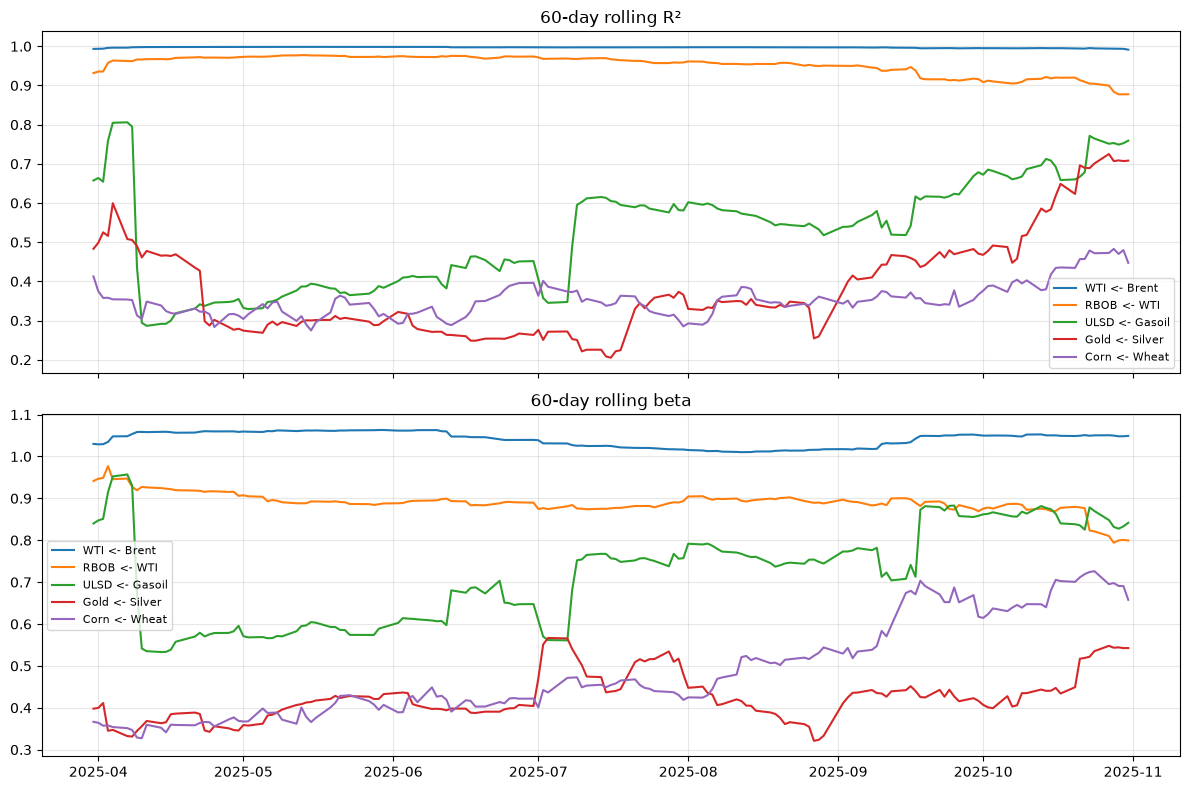

,median R2,IQR R2,min R2,% windows R2 > 0.5,beta min,beta max
WTI <- Brent,0.997,0.002,0.991,100.000,1.010,1.063
RBOB <- WTI,0.961,0.034,0.877,100.000,0.794,0.977
ULSD <- Gasoil,0.546,0.223,0.287,59.333,0.533,0.957
Gold <- Silver,0.340,0.183,0.205,14.667,0.321,0.567
Corn <- Wheat,0.348,0.053,0.275,0.000,0.327,0.726


In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
stab_rows = {}
for target, hedge in chosen_pair:
    roll = rolling_fit(returns[target], returns[hedge], 60)
    axes[0].plot(roll["r2"], label=f"{target} <- {hedge}")
    axes[1].plot(roll["beta"], label=f"{target} <- {hedge}")
    stab_rows[f"{target} <- {hedge}"] = {
        "median R2": roll["r2"].median(),
        "IQR R2": roll["r2"].quantile(0.75) - roll["r2"].quantile(0.25),
        "min R2": roll["r2"].min(),
        "% windows R2 > 0.5": (roll["r2"] > 0.5).mean() * 100,
        "beta min": roll["beta"].min(),
        "beta max": roll["beta"].max(),
    }
axes[0].set_title("60-day rolling R²")
axes[1].set_title("60-day rolling beta")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
pd.DataFrame(stab_rows).T.round(3)

In [28]:
#This is to complement the rolling window as this will use data that is separated
periods = {"Jan–Apr": ("2025-01-01", "2025-04-30"), "May–Jul": ("2025-05-01", "2025-07-31"), "Aug–Oct": ("2025-08-01", "2025-10-31")}
sub = {}
for label, (start, end) in periods.items():
    part = returns.loc[start:end]
    sub[label] = {f'{t} <- {h}' :part[t].corr(part[h]) ** 2  for t,h in chosen_pair }
    sub[label]["days"] = len(part)
pd.DataFrame(sub)


,Jan–Apr,May–Jul,Aug–Oct
WTI <- Brent,0.996947,0.997375,0.991989
RBOB <- WTI,0.961619,0.959144,0.883988
ULSD <- Gasoil,0.369009,0.563015,0.767411
Gold <- Silver,0.313817,0.349943,0.699534
Corn <- Wheat,0.414794,0.304339,0.471272
days,81.000000,63.000000,65.000000


In [29]:
rng = np.random.default_rng(42)
block = 5
repeat = 1000
row = {}
for target, hedge in chosen_pair:
    estimates = []
    for i in range(repeat):
        random_int = rng.integers(0,len(pnl) -5, size = len(pnl) // block )
        idx = np.concatenate([np.arange(s, s+block) for s in random_int])
        sample = pnl.iloc[idx]
        estimates.append(min_var_ratio(sample[target], sample[hedge]))
    row[f"{target} <- {hedge}"] = np.percentile(estimates, [2.5, 50, 97.5])
pd.DataFrame(row)



,WTI <- Brent,RBOB <- WTI,ULSD <- Gasoil,Gold <- Silver,Corn <- Wheat
0,0.968291,1.037652,0.875136,0.660845,0.288550
1,0.981741,1.086439,1.108252,0.838791,0.357628
2,0.994807,1.127011,1.304065,1.028535,0.431787


In the bootstrap table, the three rows are the 2.5th percentile, the median and the 97.5th percentile of h*.

### Interpretation

- **WTI/Brent is extremely stable:** rolling R² never falls below 0.99, beta stays within 1.01–1.06, and the bootstrap interval for h* is tight (0.97–0.99).
- **RBOB/WTI is stable but weakened in Aug–Oct** (R² 0.88, against 0.96 earlier).
- **ULSD/Gasoil and gold/silver depend on the period:** R² ranges from about 0.2–0.4 up to 0.7–0.8, and both tightened in Aug–Oct. For gold/silver the bootstrap interval for h* is wide (0.66–1.03), so the "right" number of contracts is uncertain.
- **Corn/wheat:** R² is steady but low (about 0.3–0.5), while beta drifts from 0.33 to 0.73, so the hedge ratio would need frequent re-estimation.

> **Takeaway:** only the crude and gasoline hedges are stable enough to set once and leave. For the others, a desk should re-estimate on a rolling basis and rebalance when the ratio moves.

## 10. Out-of-Sample Hedge Validation

**Purpose.** Test the hedge on data that was not used to estimate it. The ratio h* is estimated on the first 70% of days (3 Jan – 4 Aug 2025) and then applied, unchanged, to the last 30% (5 Aug – 31 Oct).

$$\text{HE} = 1 - \frac{\text{Var}(\text{hedged})}{\text{Var}(\text{unhedged})}$$

Hedge effectiveness (HE) of 1 means the hedge removes all of the variance of the daily P&L; 0 means it removes none.

In [30]:
ratio = 0.7

print(f'The train data is from ', pnl.index[0].date() , ' to ', pnl.index[int(len(pnl)*ratio) -1 ].date() )
print(f'The test data is from ', pnl.index[int(len(pnl)*ratio) ].date() , ' to ', pnl.index[-1].date())
out_of_sample = pd.DataFrame({
    f'{target} <- {hedge}': oos_test(pnl, target,hedge, ratio) for target, hedge in chosen_pair
})
out_of_sample

The train data is from  2025-01-03  to  2025-08-04
The test data is from  2025-08-05  to  2025-10-31


,WTI <- Brent,RBOB <- WTI,ULSD <- Gasoil,Gold <- Silver,Corn <- Wheat
h* (train),0.980105,1.105964,1.029863,0.732394,0.314519
HE in-sample,0.997000,0.961095,0.506348,0.291582,0.347119
HE out-sample,0.991463,0.874213,0.743964,0.690858,0.398818


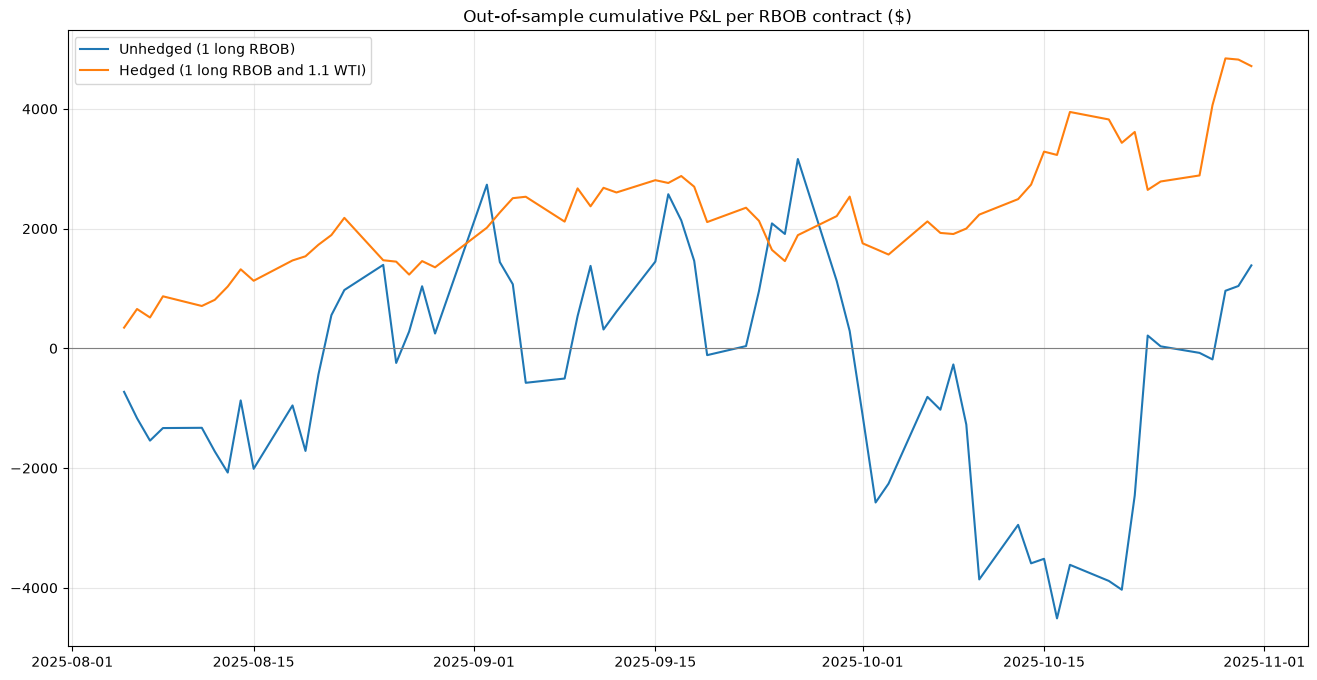

In [31]:
#compute out of sample profit for RBOB ← WTI pair. Compare both hedged and unhedged for RBOB
train, test = pnl.iloc[:int(len(pnl)*ratio)], pnl.iloc[int(len(pnl) * ratio):]
target, hedge = "RBOB", "WTI"
hedge_ratio = min_var_ratio(train[target], train[hedge])
fig, ax = plt.subplots(figsize = (16,8))
ax.plot(test[target].cumsum(), label = 'Unhedged (1 long RBOB)')
ax.plot((test[target] - hedge_ratio * test[hedge]).cumsum(), label = f'Hedged (1 long RBOB and {hedge_ratio:.2} WTI)')
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Out-of-sample cumulative P&L per RBOB contract ($)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


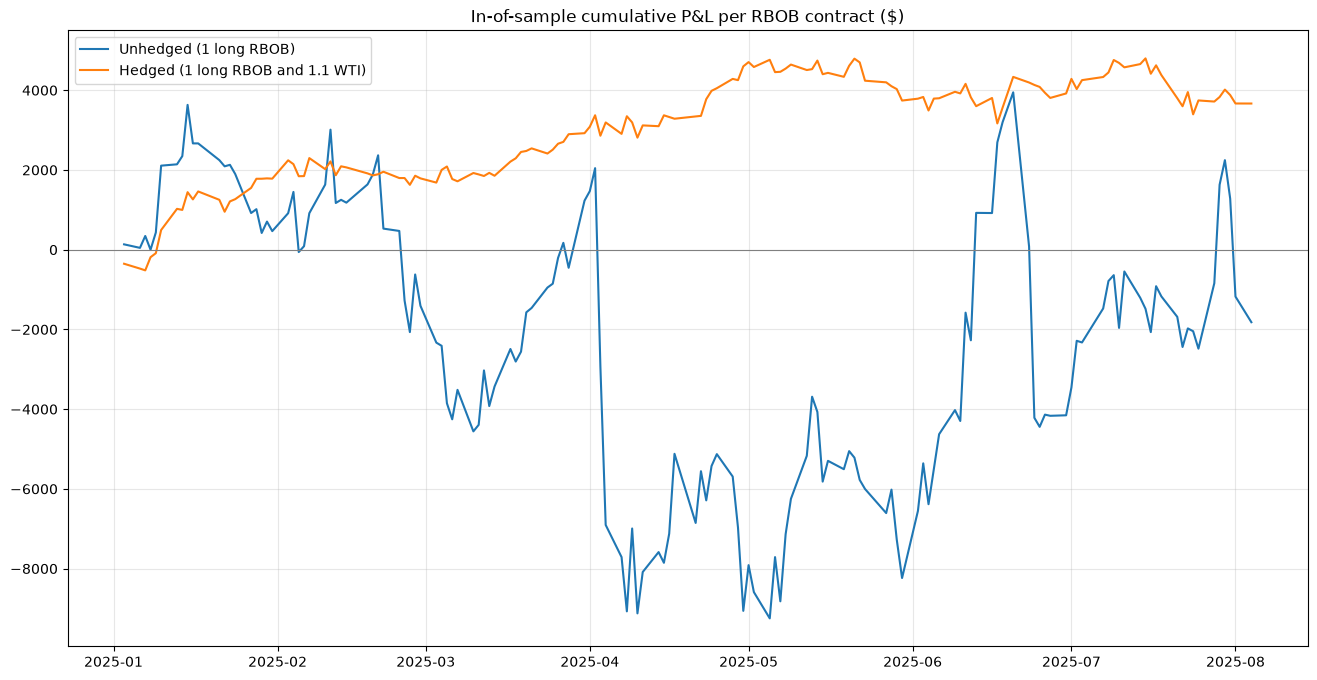

In [32]:
#Out of curious, I also want to see the in sample ones
fig, ax = plt.subplots(figsize = (16,8))
ax.plot(train[target].cumsum(), label = 'Unhedged (1 long RBOB)')
ax.plot((train[target] - hedge_ratio * train[hedge]).cumsum(), label = f'Hedged (1 long RBOB and {hedge_ratio:.2} WTI)')
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("In-of-sample cumulative P&L per RBOB contract ($)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [33]:
#Noting that just now decial was allowed, which is not usually the case in reality as contracts have to be purchased in integer value. So we need to find a way to figure how to approach this.
#Maybe we can floor it, ceil it or just round it.

#Now we have 10 contracts to be hedged. So hedge ratio can multiply by 10 also.

#The way to do it maybe that we train and see which of (floor, round, ceil ) works the best for this case, measured in terms of hedge effectiveness
int_oos = {}
for t, hd in chosen_pair:
    h = min_var_ratio(train[t], train[hd])
    exact = h * inventory
    options = {"floor": np.floor(exact), "round": np.round(exact), "ceil": np.ceil(exact)}
    he_train = {k: hedge_effectiveness(inventory * train[t], train[hd], n) for k, n in options.items()}
    chosen = max(he_train, key=he_train.get)
    n_chosen = options[chosen]
    int_oos[f"{t} <- {hd}"] = {
        "exact": round(exact, 2),
        "rule (chosen on train)": chosen,
        "contracts": int(n_chosen),
        "HE test (exact)": round(hedge_effectiveness(inventory * test[t], test[hd], exact), 3),
        "HE test (integer)": round(hedge_effectiveness(inventory * test[t], test[hd], n_chosen), 3),
    }
pd.DataFrame(int_oos).T



,exact,rule (chosen on train),contracts,HE test (exact),HE test (integer)
WTI <- Brent,9.8,round,10,0.991,0.991
RBOB <- WTI,11.06,floor,11,0.874,0.875
ULSD <- Gasoil,10.3,floor,10,0.744,0.738
Gold <- Silver,7.32,floor,7,0.691,0.679
Corn <- Wheat,3.15,floor,3,0.399,0.388


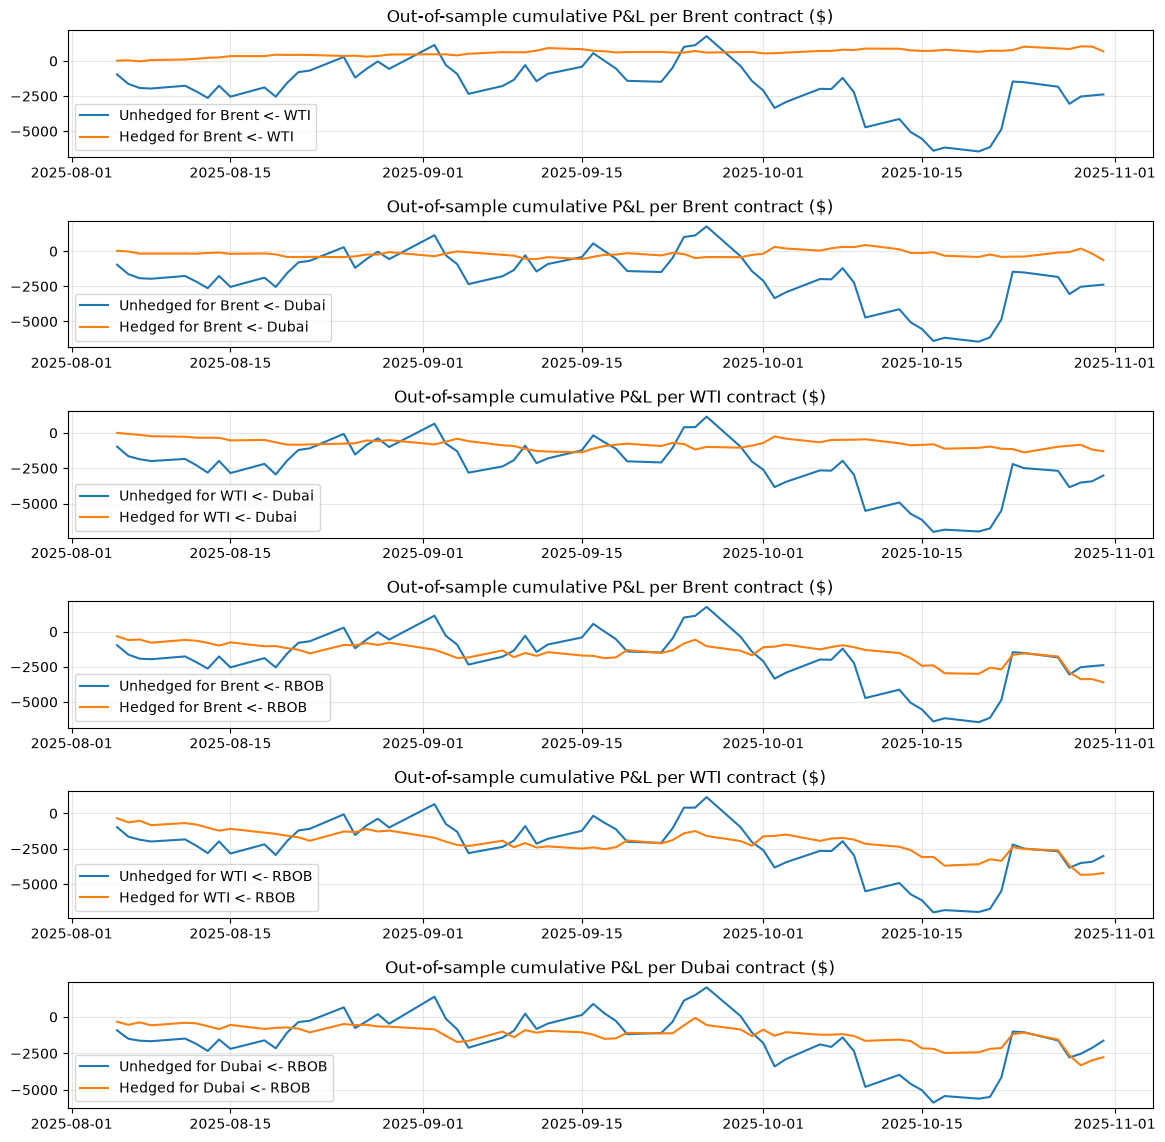

: 

In [ ]:
num = 6
top = pair_table.head(num).copy()

top[['a', 'b']] = top['pair'].str.split('/',expand = True)
top
fig, axes = plt.subplots(num,1, figsize= (14,14))
for i in range(len(top)):
    target = top.iloc[i]['a'].strip()
    hedge = top.iloc[i]['b'].strip()
    ax = axes[i]
    hedge_ratio = min_var_ratio(train[target], train[hedge])
    ax.plot(test[target].cumsum(), label = f'Unhedged for {target} <- {hedge}')
    ax.plot((test[target] - hedge_ratio*test[hedge]).cumsum(), label = f'Hedged for {target} <- {hedge}')
    ax.set_title(f"Out-of-sample cumulative P&L per {target} contract ($)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.subplots_adjust(hspace=0.5)
plt.show()


### Interpretation

- **WTI/Brent holds up out of sample:** HE 0.991, against 0.997 in-sample.
- **RBOB/WTI gets weaker,** from 0.961 to 0.874, in line with the weaker Aug–Oct sub-period in Section 9.
- **ULSD/Gasoil and gold/silver score better out of sample than in-sample** (0.74 and 0.69). This does not mean these hedges improved: the test period happened to be one in which the two relationships were tighter. It confirms that they depend on the period.
- **HE measures variance, not volatility.** An HE of 0.874 means the variance fell by 87%, but the volatility (standard deviation) of the daily P&L fell by about 64%.
- **Basis risk remains.** In the RBOB chart, the hedged P&L drifts upward and ends about USD 4,700 higher per contract. The hedge removes crude-price risk, but not the risk that gasoline moves relative to crude.
- **Whole contracts cost little:** for a 10-contract position, rounding with a rule chosen on the training data lowers out-of-sample HE by about 0.01 at most.

> **Takeaway:** the strongest in-sample hedges also work on unseen data. For the weaker pairs, a single test period can flatter or punish the hedge, so stability matters as much as the average.

## 11. Results and Desk Recommendation

For a desk holding **10 long contracts** of the target:

| Target | Primary hedge | Fallback | Hedge position | Out-of-sample HE | Stability | Caveat |
|---|---|---|---|---|---|---|
| WTI | Brent | Dubai (R² 0.98) | Short 10 Brent | 0.99 | Very stable (rolling R² ≥ 0.99) | Dubai has no volume data |
| RBOB | WTI | Brent (R² 0.94) | Short 11 WTI | 0.87 | Stable; weaker in Aug–Oct | Gasoline-against-crude spread risk remains |
| ULSD | Gasoil (tested) | Brent or WTI (higher R², 0.87) | Short 10–11 Gasoil | 0.74 | Depends on the period (R² 0.37–0.77) | Settlement-timing gap; the crude hedges were ranked but not sized here |
| Gold | Silver | None | Short 7–8 Silver | 0.69 | Depends on the period | Wide interval for h* (0.66–1.03); one silver contract is large, so rounding matters |
| Corn | Wheat | None | Short 3–4 Wheat | 0.40 | Beta drifts (0.33–0.73) | Removes less than half of the variance |
| Natural gas, coffee, copper | None | — | — | — | — | Best cross-hedge R² is 0.15 or less |

Where two numbers are shown, the first comes from the training sample (Section 10) and the second from the full sample on 31 Oct (Section 8). For the stable pairs both give the same whole number; for the unstable pairs they differ by one contract, which is itself a sign of instability.

**How a desk could use this**

- **Hedge crude and gasoline exposure with the most liquid crude contract.** These hedges remove 87–99% of the variance on unseen data.
- **Treat gold/silver and corn/wheat as partial hedges only.** They reduce risk but leave most of it, and their ratios move.
- **Do not cross-hedge natural gas, coffee or copper** with these contracts.
- **Rebalancing rule:** re-estimate the ratio on a rolling 60-day window (for example weekly) and trade only when the whole-number position changes.

## 12. Conclusion

This section summarizes the main findings and limitations.

### Answers to the research questions

1. **Which pairs have the highest R², and are they intuitive?** The crude grades (R² ≥ 0.98), then crude against RBOB (0.94) and ULSD (0.87). All are intuitive: they share crude oil as the main cost driver.
2. **Why rank by R² and not by the coefficient?** R² is symmetric and has no units. Beta depends on the direction of the regression (1.040 against 0.957 for WTI/Brent), on relative volatility and on units.
3. **What does the sign of the correlation imply?** Every meaningful correlation is positive, so a long target is hedged with a short hedge position.
4. **How stable are R², beta and the contract ratio?** The crude hedges are very stable. ULSD/Gasoil, gold/silver and corn/wheat (beta) change with the period.
5. **Do the hedges survive out of sample?** WTI/Brent yes (HE 0.99). RBOB/WTI weakens (0.87). The gold/silver result (0.69) reflects a favourable test period.
6. **How do lot sizes and units change the number of contracts?** A great deal: for RBOB/WTI a beta of 0.87 becomes 1.14 contracts. A missed cents-to-dollars conversion would give a 100-times error.
7. **Which statistical hedges are impractical?** Dubai (no volume data), Gasoil (settles at a different time), metals early in the year (thin volume), contracts near expiry (ULSD in November), and expensive hedge contracts (rounding).
8. **How could a desk use the results?** To turn an exposure into a liquid proxy hedge, keep a fallback, monitor the remaining basis risk, and rebalance on a rule.

**Sensitivity of the conclusions.** Using each pair's own overlapping dates instead of the common window leaves the ranking unchanged (Spearman 0.964). The average fall in R² (0.009) is statistically significant but small, and it comes from ULSD near its expiry.

### Limitations

1. **Short sample:** 209 daily returns over ten months, for one contract month only.
2. **Price field:** `last` is used, not the official settlement price.
3. **Dubai:** the instrument has no volume data, so its tradability is unverified.
4. **One reference date:** contract ratios are calculated on 31 Oct 2025 and drift as prices move.
5. **No trading frictions:** transaction costs, margin and bid-ask spreads are ignored.
6. **Linear, constant relationship:** one beta is assumed for the whole sample.
7. **Settlement times differ:** this is only checked with 2-day returns.
8. **Multiple comparisons:** 78 pairs are examined, and the pairs are not independent of each other.
9. **Low power:** the near-expiry test uses only 14–20 extra days.

### Extensions

- Repeat the analysis on other contract months to see whether the ranking holds.
- Use settlement prices and time-matched data for the London and New York contracts.
- Add transaction costs and compare rebalancing rules.